# RoPE (Rotary Position Embedding) in a small GPT

Reproduction of **RoFormer: Enhanced Transformer with Rotary Position Embedding** (Su, Lu, Pan, Murtadha, Wen, Liu; arXiv 2104.09864).

**What this notebook does**

1. Implements three position-encoding methods in the *same* small character-level GPT:
   - `sinusoidal` – fixed absolute encoding added to the embeddings (paper Eq. 4)
   - `learned` – trainable absolute position embedding table (paper Eq. 3)
   - `rope` – rotary position embedding applied to queries and keys (paper Eq. 14-16, 34)
2. Trains them on **TinyShakespeare** and compares validation loss / perplexity (reduced-scale analogue of paper Fig. 3, left).
3. Tests **length extrapolation**: evaluate on context lengths longer than the training context (128).
4. **Ablations**: RoPE base frequency, and no position information at all (NoPE).
5. Reproduces the long-term decay property of RoPE (paper Fig. 2).

Only plain PyTorch is used (`nn.Linear`, `nn.Embedding`, `nn.LayerNorm`, AdamW). Attention is written by hand (no flash-attention / `scaled_dot_product_attention`).
Runs on CPU or GPU. On Colab: Runtime -> Change runtime type -> GPU, then Run all.

## 1. Setup and configuration

In [1]:
import os, math, time, json, urllib.request
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

SEED = 1337
os.makedirs('figs', exist_ok=True)
os.makedirs('ckpt', exist_ok=True)

# ---------------- hyper-parameters (same for every model) ----------------
cfg = dict(
    n_layer    = 4,
    n_head     = 4,
    d_model    = 128,        # head_dim = 32
    block_size = 128,        # training context length
    dropout    = 0.1,
    batch_size = 32,
    max_steps  = 3000,
    eval_every = 100,
    lr         = 2e-3,
    min_lr     = 2e-4,
    warmup     = 100,
    weight_decay = 0.01,
    grad_clip  = 1.0,
)
MAX_LEN = 1024                                   # longest context we ever evaluate (cache size)
EVAL_LENGTHS = [32, 64, 128, 192, 256, 384, 512] # 128 = training length
print(cfg)

device: cpu
{'n_layer': 4, 'n_head': 4, 'd_model': 128, 'block_size': 128, 'dropout': 0.1, 'batch_size': 32, 'max_steps': 3000, 'eval_every': 100, 'lr': 0.002, 'min_lr': 0.0002, 'warmup': 100, 'weight_decay': 0.01, 'grad_clip': 1.0}


## 2. Data: TinyShakespeare (character level)

In [2]:
if not os.path.exists('input.txt'):
    url = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
    urllib.request.urlretrieve(url, 'input.txt')

text = open('input.txt', 'r', encoding='utf-8').read()
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)

n_train = int(0.9 * len(data))
train_data = data[:n_train].to(device)
val_data   = data[n_train:].to(device)
print('characters:', len(text), '| vocab size:', vocab_size)
print('train chars:', len(train_data), '| val chars:', len(val_data))

def get_batch(split_data, batch_size, block_size, gen):
    # random windows; `gen` is a CPU generator so every model sees the SAME batches
    ix = torch.randint(len(split_data) - block_size - 1, (batch_size,), generator=gen)
    x = torch.stack([split_data[i : i + block_size] for i in ix])
    y = torch.stack([split_data[i + 1 : i + 1 + block_size] for i in ix])
    return x, y

characters: 1115394 | vocab size: 65
train chars: 1003854 | val chars: 111540


## 3. Position encodings

**Sinusoidal (Eq. 4):** $p_{k,2t}=\sin(k/10000^{2t/d}),\; p_{k,2t+1}=\cos(k/10000^{2t/d})$, added to the token embedding.

**Learned:** a trainable table `nn.Embedding(block_size, d)`, added to the token embedding. It has no vector for positions $\ge$ `block_size`.

**RoPE (Eq. 14, 15, 34):** split each query/key vector into $d/2$ pairs $(x_{2i}, x_{2i+1})$ and rotate pair $i$ by angle $m\theta_i$ with $\theta_i = 10000^{-2(i-1)/d}$:

$$R^d_{\Theta,m}x = \begin{pmatrix}x_1\\x_2\\x_3\\x_4\\ \vdots\end{pmatrix}\otimes\begin{pmatrix}\cos m\theta_1\\ \cos m\theta_1\\ \cos m\theta_2\\ \cos m\theta_2\\ \vdots\end{pmatrix} + \begin{pmatrix}-x_2\\x_1\\-x_4\\x_3\\ \vdots\end{pmatrix}\otimes\begin{pmatrix}\sin m\theta_1\\ \sin m\theta_1\\ \sin m\theta_2\\ \sin m\theta_2\\ \vdots\end{pmatrix}$$

Because $R_m^\top R_n = R_{n-m}$, the score $q_m^\top k_n=(R_m W_q x_m)^\top(R_n W_k x_n)=x_m^\top W_q^\top R_{n-m}W_k x_n$ depends on the **relative** distance only. Nothing is added to the embeddings and the values $v$ are not rotated.

In [3]:
# ---------------- Sinusoidal (absolute, fixed) ----------------
def sinusoidal_table(max_len, d_model):
    pe = torch.zeros(max_len, d_model)
    pos = torch.arange(max_len).float().unsqueeze(1)                      # (max_len, 1)
    div = 10000.0 ** (torch.arange(0, d_model, 2).float() / d_model)      # 10000^(2t/d)
    pe[:, 0::2] = torch.sin(pos / div)
    pe[:, 1::2] = torch.cos(pos / div)
    return pe

# ---------------- RoPE ----------------
def build_rope_cache(head_dim, max_len, base=10000.0):
    # theta_i = base^(-2(i-1)/d) for i = 1..d/2   (paper Eq. 15)
    two_i = torch.arange(0, head_dim, 2).float()        # 0, 2, 4, ..., d-2
    theta = base ** (-two_i / head_dim)                 # (d/2,)
    m = torch.arange(max_len).float()                   # positions 0..max_len-1
    angles = torch.outer(m, theta)                      # (max_len, d/2) = m * theta_i
    cos = angles.cos().repeat_interleave(2, dim=-1)     # (max_len, d): cos m*t1, cos m*t1, cos m*t2, ...
    sin = angles.sin().repeat_interleave(2, dim=-1)
    return cos, sin

def rotate_pairs(x):
    # (x1, x2, x3, x4, ...) -> (-x2, x1, -x4, x3, ...)
    x1 = x[..., 0::2]
    x2 = x[..., 1::2]
    return torch.stack((-x2, x1), dim=-1).flatten(-2)

def apply_rope(x, cos, sin):
    # x: (B, n_head, T, head_dim); cos, sin: (T, head_dim)   -- paper Eq. 34
    return x * cos + rotate_pairs(x) * sin

### Sanity checks for RoPE (these are the properties you derive on the board)

In [4]:
# 1) rotation is orthogonal -> vector norm is unchanged
# 2) <R_m q, R_n k> depends only on (n - m): shifting both positions by the same amount changes nothing
torch.manual_seed(0)
hd = 32
cos, sin = build_rope_cache(hd, 64)
q = torch.randn(1, 1, 1, hd)
k = torch.randn(1, 1, 1, hd)

def score(m, n):
    qm = apply_rope(q, cos[m:m+1], sin[m:m+1])
    kn = apply_rope(k, cos[n:n+1], sin[n:n+1])
    return (qm * kn).sum().item()

print('norm before / after rotation :', q.norm().item(), apply_rope(q, cos[7:8], sin[7:8]).norm().item())
print('score(m=5,  n=2 ) =', score(5, 2))
print('score(m=30, n=27) =', score(30, 27), '  (same relative distance 3)')
print('score(m=41, n=38) =', score(41, 38), '  (same relative distance 3)')
print('score(m=5,  n=3 ) =', score(5, 3), '  (different distance 2)')
assert abs(score(5, 2) - score(30, 27)) < 1e-4 and abs(score(5, 2) - score(41, 38)) < 1e-4
print('relative-position property verified')

norm before / after rotation : 5.691975116729736 5.691975116729736
score(m=5,  n=2 ) = -3.482755184173584
score(m=30, n=27) = -3.4827544689178467   (same relative distance 3)
score(m=41, n=38) = -3.482755422592163   (same relative distance 3)
score(m=5,  n=3 ) = -3.7365260124206543   (different distance 2)
relative-position property verified


## 4. The GPT model

In [5]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_head, pos_type, max_len, rope_base, dropout):
        super().__init__()
        assert d_model % n_head == 0
        self.n_head = n_head
        self.head_dim = d_model // n_head
        self.pos_type = pos_type
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.proj = nn.Linear(d_model, d_model)
        self.attn_drop = nn.Dropout(dropout)
        self.resid_drop = nn.Dropout(dropout)
        if pos_type == 'rope':
            cos, sin = build_rope_cache(self.head_dim, max_len, rope_base)
            self.register_buffer('cos', cos, persistent=False)
            self.register_buffer('sin', sin, persistent=False)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)   # (B, H, T, hd)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        if self.pos_type == 'rope':                  # rotate q and k only (not v)
            q = apply_rope(q, self.cos[:T], self.sin[:T])
            k = apply_rope(k, self.cos[:T], self.sin[:T])

        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)     # (B, H, T, T)
        mask = torch.tril(torch.ones(T, T, device=x.device)).bool()
        att = att.masked_fill(~mask, float('-inf'))
        att = F.softmax(att, dim=-1)
        att = self.attn_drop(att)
        y = att @ v                                                    # (B, H, T, hd)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_drop(self.proj(y))


class Block(nn.Module):
    def __init__(self, d_model, n_head, pos_type, max_len, rope_base, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_head, pos_type, max_len, rope_base, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, 4 * d_model), nn.GELU(),
            nn.Linear(4 * d_model, d_model), nn.Dropout(dropout))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x


class GPT(nn.Module):
    # pos_type: 'sinusoidal' | 'learned' | 'rope' | 'none'
    def __init__(self, vocab_size, pos_type, n_layer, n_head, d_model, block_size,
                 dropout=0.1, max_len=MAX_LEN, rope_base=10000.0):
        super().__init__()
        self.pos_type = pos_type
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        if pos_type == 'learned':
            self.pos_emb = nn.Embedding(block_size, d_model)
        elif pos_type == 'sinusoidal':
            self.register_buffer('pe', sinusoidal_table(max_len, d_model), persistent=False)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList(
            [Block(d_model, n_head, pos_type, max_len, rope_base, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.tok_emb(idx)
        if self.pos_type == 'learned':
            assert T <= self.block_size, 'learned positions only exist up to block_size'
            x = x + self.pos_emb(torch.arange(T, device=idx.device))
        elif self.pos_type == 'sinusoidal':
            x = x + self.pe[:T]
        x = self.drop(x)
        for blk in self.blocks:
            x = blk(x)
        logits = self.head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

## 5. Training and evaluation helpers

In [6]:
def get_lr(step):
    # linear warm-up, then cosine decay to min_lr
    if step < cfg['warmup']:
        return cfg['lr'] * (step + 1) / cfg['warmup']
    progress = (step - cfg['warmup']) / max(1, cfg['max_steps'] - cfg['warmup'])
    return cfg['min_lr'] + 0.5 * (cfg['lr'] - cfg['min_lr']) * (1 + math.cos(math.pi * progress))


@torch.no_grad()
def evaluate(model, seq_len, max_chunks=None, batch=16):
    # Cut the validation text into non-overlapping windows of length seq_len and average the
    # cross-entropy over every position. Also returns the loss per position inside the window.
    model.eval()
    n = (len(val_data) - 1) // seq_len
    if max_chunks is not None:
        n = min(n, max_chunks)
    x = val_data[: n * seq_len].view(n, seq_len)
    y = val_data[1 : n * seq_len + 1].view(n, seq_len)
    pos_loss = torch.zeros(seq_len)
    for i in range(0, n, batch):
        xb, yb = x[i : i + batch], y[i : i + batch]
        logits, _ = model(xb)
        l = F.cross_entropy(logits.reshape(-1, logits.size(-1)), yb.reshape(-1), reduction='none')
        pos_loss += l.view(xb.size(0), seq_len).sum(0).cpu()
    pos_loss /= n
    model.train()
    return pos_loss.mean().item(), pos_loss


def train_model(name, pos_type, rope_base=10000.0):
    torch.manual_seed(SEED)
    model = GPT(vocab_size, pos_type, cfg['n_layer'], cfg['n_head'], cfg['d_model'],
                cfg['block_size'], cfg['dropout'], MAX_LEN, rope_base).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    print(f'\n=== {name}  (pos_type={pos_type}, rope_base={rope_base}, params={n_params:,}) ===')

    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    gen = torch.Generator().manual_seed(SEED)           # same batch order for every model
    hist = dict(step=[], train_loss=[], val_loss=[])
    run_loss, run_n = 0.0, 0
    t0 = time.time()
    model.train()
    for step in range(cfg['max_steps']):
        for g in opt.param_groups:
            g['lr'] = get_lr(step)
        xb, yb = get_batch(train_data, cfg['batch_size'], cfg['block_size'], gen)
        _, loss = model(xb, yb)
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
        opt.step()
        run_loss += loss.item(); run_n += 1

        if (step + 1) % cfg['eval_every'] == 0 or step == 0:
            val_loss, _ = evaluate(model, cfg['block_size'], max_chunks=100)
            hist['step'].append(step + 1)
            hist['train_loss'].append(run_loss / run_n)
            hist['val_loss'].append(val_loss)
            print(f'step {step+1:5d} | train {run_loss/run_n:.4f} | val {val_loss:.4f} | {time.time()-t0:.0f}s')
            run_loss, run_n = 0.0, 0

    # final evaluation at the training length and at longer lengths
    extrap = {}
    pos_loss_512 = None
    for L in EVAL_LENGTHS:
        if pos_type == 'learned' and L > cfg['block_size']:
            extrap[L] = None                            # no position vectors exist beyond block_size
            continue
        l, pl = evaluate(model, L)
        extrap[L] = l
        if L == 512:
            pos_loss_512 = pl.tolist()
    final_val, _ = evaluate(model, cfg['block_size'])    # full validation set at L=128
    out = dict(name=name, pos_type=pos_type, rope_base=rope_base, params=n_params,
               hist=hist, final_val_loss=final_val, final_val_ppl=math.exp(final_val),
               extrap_loss={str(k): v for k, v in extrap.items()},
               pos_loss_512=pos_loss_512, train_time_s=time.time() - t0)
    print(f'FINAL {name}: val loss {final_val:.4f} | perplexity {math.exp(final_val):.3f}')
    return out

## 6. Main experiment: absolute (sinusoidal) vs learned vs rotary

All three models have identical depth/width, optimiser, schedule, seed and **identical training batches**. The only change is how position is injected.

In [7]:
results = {}
for name, pos_type in [('sinusoidal', 'sinusoidal'), ('learned', 'learned'), ('rope', 'rope')]:
    results[name] = train_model(name, pos_type)
    json.dump(results, open('results.json', 'w'))


=== sinusoidal  (pos_type=sinusoidal, rope_base=10000.0, params=810,049) ===


step     1 | train 4.3887 | val 4.3786 | 1s


step   100 | train 2.9392 | val 2.4993 | 33s


step   200 | train 2.4263 | val 2.2863 | 64s


step   300 | train 2.2484 | val 2.1132 | 96s


step   400 | train 2.1154 | val 2.0363 | 128s


... (87 outputs left out)

step  2800 | train 1.3804 | val 1.3862 | 935s


step  2900 | train 1.3792 | val 1.3845 | 968s


step  3000 | train 1.3730 | val 1.3841 | 1002s


FINAL rope: val loss 1.5298 | perplexity 4.617


## 7. Ablations

* **RoPE base frequency**: the paper uses $\theta_i = 10000^{-2(i-1)/d}$. We try base 100 (high frequencies only, decays too fast) and base 1,000,000 (very slow rotation).
* **NoPE**: the same GPT with *no* position information at all. A causal model can in principle infer position from the mask, so this shows how much the explicit encoding really matters.

In [8]:
for name, pos_type, base in [('rope_base100', 'rope', 100.0),
                             ('rope_base1e6', 'rope', 1000000.0),
                             ('nope', 'none', 10000.0)]:
    results[name] = train_model(name, pos_type, rope_base=base)
    json.dump(results, open('results.json', 'w'))


=== rope_base100  (pos_type=rope, rope_base=100.0, params=810,049) ===


step     1 | train 4.3630 | val 4.3580 | 1s


step   100 | train 2.8299 | val 2.1986 | 34s


step   200 | train 2.0861 | val 1.9669 | 67s


step   300 | train 1.8878 | val 1.8192 | 101s


step   400 | train 1.7891 | val 1.7807 | 134s


... (87 outputs left out)

step  2800 | train 1.7012 | val 1.6467 | 869s


step  2900 | train 1.6984 | val 1.6453 | 900s


step  3000 | train 1.6916 | val 1.6449 | 931s


FINAL nope: val loss 1.7658 | perplexity 5.846


## 8. Results

In [9]:
# ---- Table 1: perplexity vs context length ----
order = ['sinusoidal', 'learned', 'rope', 'rope_base100', 'rope_base1e6', 'nope']
print('Validation PERPLEXITY (char level). Training context = 128. "-" = not defined.')
print(f"{'model':14s}" + ''.join(f'{L:>9d}' for L in EVAL_LENGTHS))
for name in order:
    row = f'{name:14s}'
    for L in EVAL_LENGTHS:
        v = results[name]['extrap_loss'][str(L)]
        row += f'{math.exp(v):9.3f}' if v is not None else f'{"-":>9s}'
    print(row)

print()
print('Parameters and final validation loss / perplexity at L = 128')
for name in order:
    r = results[name]
    print(f"{name:14s} params={r['params']:>8,d}  loss={r['final_val_loss']:.4f}  ppl={r['final_val_ppl']:.3f}")

Validation PERPLEXITY (char level). Training context = 128. "-" = not defined.
model                32       64      128      192      256      384      512
sinusoidal        5.208    5.017    4.912    8.193   11.136   14.933   17.226
learned           5.172    4.983    4.880        -        -        -        -
rope              4.946    4.729    4.617    4.928    6.895   12.311   17.931
rope_base100      4.969    4.756    4.645    5.366    7.599   12.269   15.977
rope_base1e6      4.908    4.695    4.586    6.675    9.752   15.533   20.943
nope              6.080    5.894    5.846    6.082    6.711    8.111    9.155

Parameters and final validation loss / perplexity at L = 128
sinusoidal     params= 810,049  loss=1.5916  ppl=4.912
learned        params= 826,433  loss=1.5851  ppl=4.880
rope           params= 810,049  loss=1.5298  ppl=4.617
rope_base100   params= 810,049  loss=1.5359  ppl=4.645
rope_base1e6   params= 810,049  loss=1.5230  ppl=4.586
nope           params= 810,049  loss=1

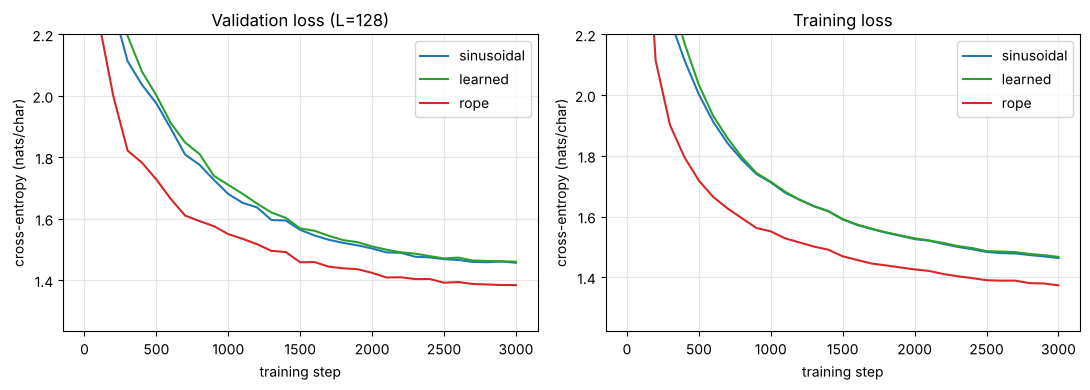

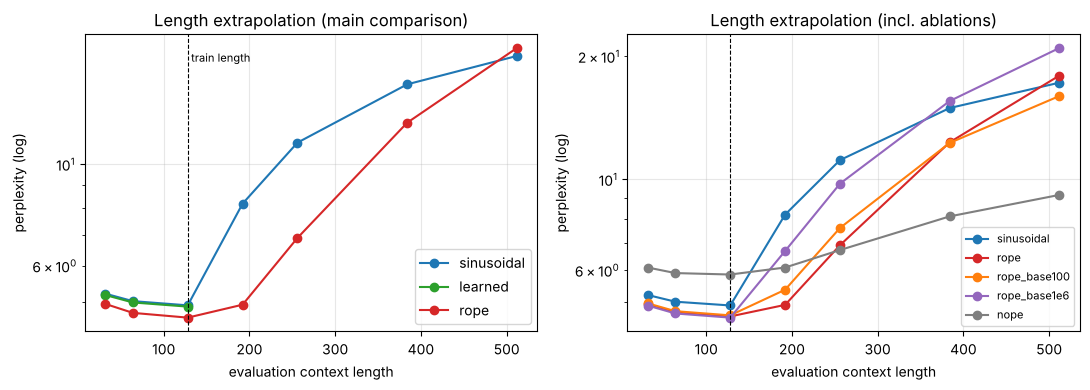

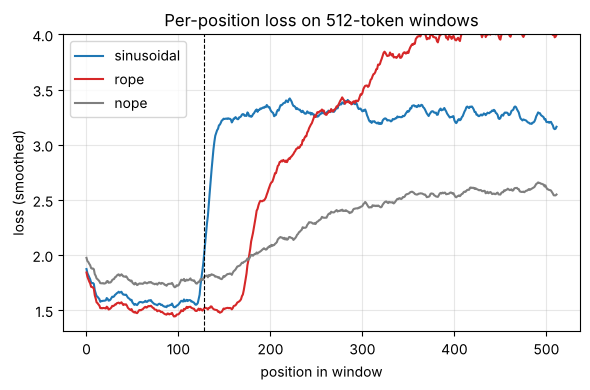

In [10]:
# ---- Figure A: validation loss curves (analogue of paper Fig. 3, left) ----
colors = dict(sinusoidal='tab:blue', learned='tab:green', rope='tab:red',
              rope_base100='tab:orange', rope_base1e6='tab:purple', nope='tab:gray')
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name in ['sinusoidal', 'learned', 'rope']:
    h = results[name]['hist']
    ax[0].plot(h['step'], h['val_loss'], label=name, color=colors[name])
    ax[1].plot(h['step'], h['train_loss'], label=name, color=colors[name])
ax[0].set_title('Validation loss (L=128)'); ax[1].set_title('Training loss')
for a in ax:
    a.set_xlabel('training step'); a.set_ylabel('cross-entropy (nats/char)'); a.legend(); a.grid(alpha=0.3)
ax[0].set_ylim(top=2.2); ax[1].set_ylim(top=2.2)
plt.tight_layout(); plt.savefig('figs/loss_curves.png', dpi=200); plt.show()

# ---- Figure B: length extrapolation ----
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name in ['sinusoidal', 'learned', 'rope']:
    xs = [L for L in EVAL_LENGTHS if results[name]['extrap_loss'][str(L)] is not None]
    ys = [math.exp(results[name]['extrap_loss'][str(L)]) for L in xs]
    ax[0].plot(xs, ys, marker='o', label=name, color=colors[name])
ax[0].axvline(cfg['block_size'], color='k', ls='--', lw=0.8); ax[0].text(cfg['block_size']+4, ax[0].get_ylim()[1]*0.9, 'train length', fontsize=8)
ax[0].set_yscale('log'); ax[0].set_xlabel('evaluation context length'); ax[0].set_ylabel('perplexity (log)')
ax[0].set_title('Length extrapolation (main comparison)'); ax[0].legend(); ax[0].grid(alpha=0.3)
for name in order:
    if name in ('learned',): continue
    xs = EVAL_LENGTHS
    ys = [math.exp(results[name]['extrap_loss'][str(L)]) for L in xs]
    ax[1].plot(xs, ys, marker='o', label=name, color=colors[name])
ax[1].axvline(cfg['block_size'], color='k', ls='--', lw=0.8)
ax[1].set_yscale('log'); ax[1].set_xlabel('evaluation context length'); ax[1].set_ylabel('perplexity (log)')
ax[1].set_title('Length extrapolation (incl. ablations)'); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig('figs/extrapolation.png', dpi=200); plt.show()

# ---- Figure C: loss at each position inside a 512-token window ----
def smooth(v, w=8):
    return [sum(v[max(0, i-w):i+w+1]) / len(v[max(0, i-w):i+w+1]) for i in range(len(v))]
plt.figure(figsize=(6, 4))
for name in ['sinusoidal', 'rope', 'nope']:
    plt.plot(smooth(results[name]['pos_loss_512']), label=name, color=colors[name])
plt.axvline(cfg['block_size'], color='k', ls='--', lw=0.8)
plt.xlabel('position in window'); plt.ylabel('loss (smoothed)'); plt.ylim(top=4)
plt.title('Per-position loss on 512-token windows'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('figs/position_loss.png', dpi=200); plt.show()

## 9. Long-term decay of RoPE (paper Fig. 2)

Section 3.4.3 shows $|\sum_i h_i e^{i(m-n)\theta_i}|$ is controlled by $\frac{1}{d/2}\sum_i |S_i|$, with $S_j=\sum_{i<j}e^{i(m-n)\theta_i}$. We compute this quantity for $d=256$ and $\theta_i=10000^{-2i/d}$ and plot it against the relative distance.

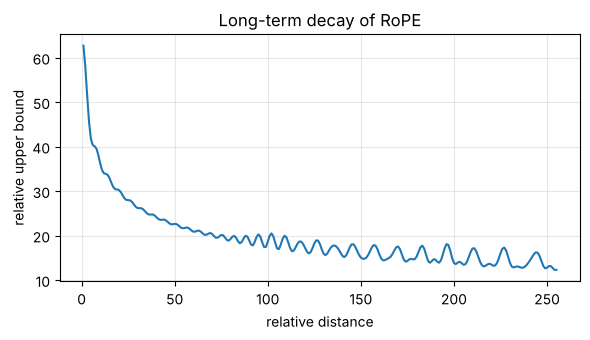

mean value, distance 1-10   : 45.36635971069336
mean value, distance 100-110: 18.93552017211914
mean value, distance 240-255: 13.987080574035645


In [11]:
d = 256
rel = torch.arange(0, 256).float()                                       # relative distance m-n
theta = 10000.0 ** (-2 * torch.arange(d // 2).float() / d)                # (d/2,)
phase = torch.outer(rel, theta)                                           # (256, d/2)
terms = torch.polar(torch.ones_like(phase), phase)                        # e^{i (m-n) theta_i}
S = torch.cumsum(terms, dim=1)                                            # S_{j+1} = sum_{i<=j} e^{...}
upper = S.abs().mean(dim=1)                                               # (1/(d/2)) sum_i |S_i|

plt.figure(figsize=(6, 3.5))
plt.plot(rel[1:].numpy(), upper[1:].numpy())
plt.xlabel('relative distance'); plt.ylabel('relative upper bound'); plt.title('Long-term decay of RoPE')
plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig('figs/decay.png', dpi=200); plt.show()
print('mean value, distance 1-10   :', upper[1:11].mean().item())
print('mean value, distance 100-110:', upper[100:111].mean().item())
print('mean value, distance 240-255:', upper[240:256].mean().item())

## 10. Notes for the report / viva

* Same seed, same batch order, same hyper-parameters for all models. Single seed (compute limit) - differences of about 0.01 nats should not be over-interpreted.
* The learned table has `block_size x d_model` extra parameters; sinusoidal and RoPE have none.
* `learned` cannot be evaluated beyond 128 tokens (no embedding exists), which is itself a result.
* Everything in `results.json` and `figs/` is produced by this notebook.